# Praktikum 5 - Klasifikasi Citra Siang dan Malam

Praktikum ini melakukan klasifikasi dua label citra, yaitu **day** (siang) dan **night** (malam). Alur percobaan mencakup pra-pengolahan citra, ekstraksi fitur sederhana berupa rata-rata kecerahan (average brightness), klasifikasi dengan threshold, lalu klasifikasi dengan SVM.

Dataset gambar diletakkan pada folder `images/` dengan struktur:

```
images/
├── training/
│   ├── day/
│   └── night/
└── test/
    ├── day/
    └── night/
```

Pada Google Colab, folder `images/` dapat diunggah ke Google Drive. Notebook akan mencari lokasinya secara otomatis.

## Langkah 0 - Import Library

In [11]:
# Import required libraries
import os
import sys
import random
from pathlib import Path

import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

## Langkah 0b - Pastikan OpenCV Tersedia

OpenCV dipakai untuk resize citra dan konversi warna RGB ke HSV. Jika belum tersedia, cell berikut memasang `opencv-python-headless` secara otomatis.

In [12]:
try:
    import cv2
except ImportError:
    import subprocess
    subprocess.check_call([
        sys.executable, '-m', 'pip', 'install', '-q', 'opencv-python-headless'
    ])
    import cv2

print('OpenCV:', cv2.__version__)

OpenCV: 5.0.0


## Langkah 0c - Mount Google Drive (Opsional)

Cell ini hanya berjalan di Google Colab. Jika dataset sudah berada di folder notebook, cell ini boleh dilewati.

In [13]:
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
else:
    print('Bukan Google Colab, mount Drive dilewati.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Langkah 0d - Tentukan Lokasi Dataset

Isi `DATA_DIR` secara manual bila lokasi folder berbeda. Jika `DATA_DIR` dibiarkan `None`, notebook akan mencoba beberapa lokasi umum.

In [14]:
DATA_DIR = '/content/drive/MyDrive/dataset ml /images /images'

CANDIDATES = [
    DATA_DIR,
    'images',
    '/content/images',
    '/content/drive/MyDrive/images',
    '/content/drive/MyDrive/images/images',
    '/content/drive/MyDrive/dataset ml/images',
    '/content/drive/MyDrive/dataset ml/images/images',
]


def find_data_dir(candidates):
    for candidate in candidates:
        if not candidate:
            continue
        path = Path(candidate)
        if (path / 'training').is_dir() and (path / 'test').is_dir():
            return path
    return None


data_dir = find_data_dir(CANDIDATES)

if data_dir is None:
    raise FileNotFoundError(
        "Folder images tidak ditemukan. Pastikan struktur berisi "
        "'training/' dan 'test/', lalu isi DATA_DIR di atas."
    )

train_dir = data_dir / 'training'
test_dir = data_dir / 'test'

print('Lokasi dataset :', data_dir)
print('Folder training:', train_dir)
print('Folder test    :', test_dir)

Lokasi dataset : /content/drive/MyDrive/dataset ml /images /images
Folder training: /content/drive/MyDrive/dataset ml /images /images/training
Folder test    : /content/drive/MyDrive/dataset ml /images /images/test


## Langkah 1 - Load Data dan Visualisasi

Fungsi `load_dataset` membaca semua gambar dari subfolder `day` dan `night`, lalu menyimpannya sebagai pasangan `(gambar, label)`.

Gambar dikonversi ke `uint8` dengan rentang 0-255. Tanpa konversi ini, PNG akan terbaca sebagai `float` 0-1 sehingga perhitungan brightness tidak sesuai.

In [15]:
def load_dataset(img_dir):
    p = Path(img_dir)
    img_list = []

    for folder in sorted(x for x in p.iterdir() if x.is_dir()):
        label = folder.name
        files = sorted(list(folder.glob('*.jpg')) + list(folder.glob('*.png')))

        for file in files:
            img = mpimg.imread(file)

            if img is None:
                continue

            # PNG dapat terbaca sebagai float 0-1, ubah ke uint8 0-255
            if img.dtype != np.uint8:
                img = np.clip(img * 255, 0, 255).astype(np.uint8)

            # Buang channel alpha bila ada
            if img.ndim == 3 and img.shape[2] == 4:
                img = img[:, :, :3]

            img_list.append((img, label))

    return img_list

In [16]:
# Load training data
train_img = load_dataset(train_dir)

print('Jumlah gambar training:', len(train_img))

Jumlah gambar training: 240


In [17]:
# Cek data pertama, harus berupa tuple (array gambar, label)
train_img[0]

(array([[[158, 194, 218],
         [158, 194, 218],
         [158, 194, 218],
         ...,
         [176, 209, 228],
         [177, 210, 229],
         [177, 210, 229]],
 
        [[158, 194, 218],
         [158, 194, 218],
         [158, 194, 218],
         ...,
         [180, 213, 232],
         [180, 213, 232],
         [180, 213, 232]],
 
        [[158, 194, 218],
         [158, 194, 218],
         [158, 194, 218],
         ...,
         [177, 210, 229],
         [177, 210, 229],
         [177, 210, 229]],
 
        ...,
 
        [[ 35,  40,  43],
         [ 38,  43,  46],
         [ 39,  44,  47],
         ...,
         [ 65,  73,  75],
         [ 65,  73,  75],
         [ 65,  73,  75]],
 
        [[ 36,  41,  44],
         [ 38,  43,  46],
         [ 39,  44,  47],
         ...,
         [ 68,  76,  78],
         [ 68,  76,  78],
         [ 65,  73,  75]],
 
        [[ 36,  41,  44],
         [ 38,  43,  46],
         [ 39,  44,  47],
         ...,
         [ 68,  76,  78],
  

In [18]:
# Cek ukuran gambar secara acak
pick_random = np.random.randint(0, len(train_img))

print(f'Image {pick_random}')
print(train_img[pick_random][0].shape)

Image 188
(700, 1280, 3)


In [19]:
# Fungsi untuk visualisasi
def random_img_viz(img_list):
    rand_num = np.random.randint(0, len(img_list))

    img = img_list[rand_num][0]
    label = img_list[rand_num][1]

    plt.imshow(img)
    plt.axis('off')
    plt.show()

    print(f'Shape\t: {img.shape}')
    print(f'Label\t: {label}')

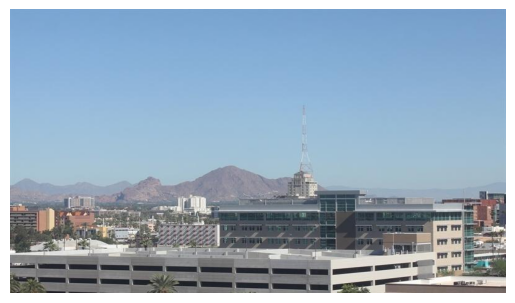

Shape	: (458, 800, 3)
Label	: day


In [20]:
# Visualisasi gambar acak
random_img_viz(train_img)

## Langkah 2 - Pra Pengolahan Data

Tahap ini melakukan standardisasi ukuran gambar dan encoding label.

- Semua gambar di-resize ke **1100 x 600** piksel.
- Label `day` di-encode menjadi `1` dan `night` menjadi `0`.

In [21]:
def standarized_input(image):
    # resize to w: 1100, h: 600
    std_img = cv2.resize(image, (1100, 600))

    return std_img

In [22]:
def label_encoder(label):
    # Encode the label
    # day as 1; night as 0
    num_val = 0

    if label == 'day':
        num_val = 1

    return num_val

In [23]:
def preprocess(img_list):
    std_img_list = []

    for item in img_list:
        image = item[0]
        label = item[1]

        # Standarized the image
        std_img = standarized_input(image)

        # Create the label
        img_label = label_encoder(label)

        std_img_list.append((std_img, img_label))

    return std_img_list

In [24]:
# Pra pengolahan data training
train_std_img_list = preprocess(train_img)

print('Jumlah gambar setelah preprocess:', len(train_std_img_list))

Jumlah gambar setelah preprocess: 240


In [25]:
# Cek ukuran gambar setelah preprocess
pick_random = np.random.randint(0, len(train_std_img_list))

print(f'Image {pick_random}')
print(train_std_img_list[pick_random][0].shape)

Image 0
(600, 1100, 3)


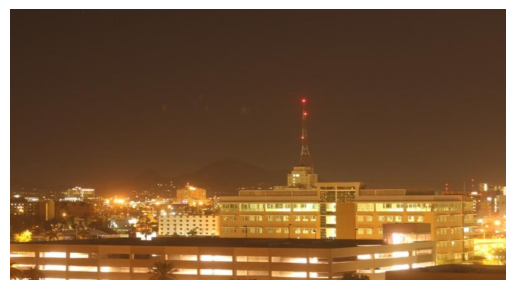

Shape	: (600, 1100, 3)
Label	: 0


In [26]:
# Inspeksi visual hasil preprocess
random_img_viz(train_std_img_list)

## Langkah 3 - Ekstraksi Fitur

Fitur yang digunakan adalah rata-rata kecerahan gambar. Gambar dikonversi dari RGB ke HSV, lalu diambil nilai rata-rata channel **V** (value/brightness).

In [27]:
# Get feature based on average brightness using HSV colorspace
def avg_brightness(image):
    # Convert image to HSV
    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

    # Calculate the avg of brightness
    sum_brightness = np.sum(img_hsv[:, :, 2])  # take the 3rd value which is the V channel
    area = image.shape[0] * image.shape[1]
    avg = sum_brightness / area

    return avg

Image 194
Label: 0
Avg Brightness: 99.0812


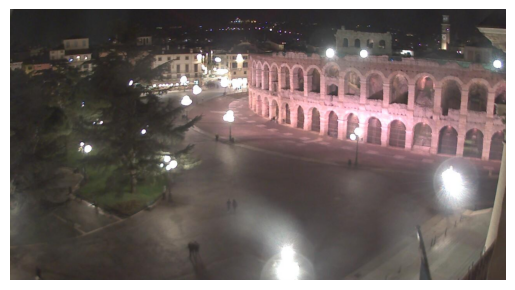

In [28]:
# Cek pada gambar acak hasil preprocess
rand_img = np.random.randint(0, len(train_std_img_list))

feature_img = train_std_img_list[rand_img][0]

avg_img = avg_brightness(feature_img)

print(f'Image {rand_img}')
print(f'Label: {train_std_img_list[rand_img][1]}')
print(f'Avg Brightness: {avg_img:.4f}')

plt.imshow(feature_img)
plt.axis('off')
plt.show()

## Langkah 4 - Klasifikasi dengan Metode Threshold

Klasifikasi sederhana dilakukan dengan membandingkan rata-rata kecerahan terhadap nilai ambang batas yang ditentukan sendiri.

In [29]:
def predict_label(img, threshold):
    # Compute average brightness
    avg = avg_brightness(img)
    pred = 0

    # Predict the label based on user defined threshold
    if avg > threshold:
        pred = 1

    return pred

Image 89
Actual label: 1
Predicted label: 0


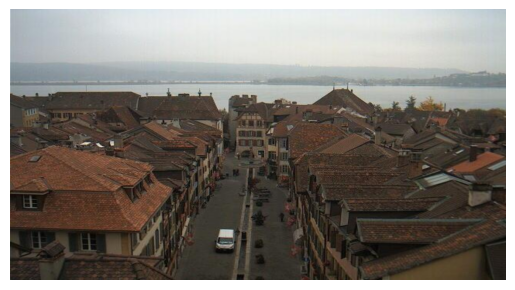

In [30]:
# Uji classifier threshold pada data training
rand_img = np.random.randint(0, len(train_std_img_list))

pred = predict_label(train_std_img_list[rand_img][0], threshold=120)

print(f'Image {rand_img}')
print(f'Actual label: {train_std_img_list[rand_img][1]}')
print(f'Predicted label: {pred}')

plt.imshow(train_std_img_list[rand_img][0])
plt.axis('off')
plt.show()

## Langkah 5 - Evaluasi Manual

Evaluasi dilakukan dengan membandingkan hasil prediksi terhadap label sebenarnya untuk seluruh data.

In [31]:
def evaluate(img_list, threshold):
    miss_labels = []

    for file in img_list:
        # Get the ground truth / correct label
        img = file[0]
        label = file[1]

        # Get prediction
        pred_label = predict_label(img, threshold)

        # Compare ground truth and pred
        if pred_label != label:
            miss_labels.append((img, pred_label, label))

    total_img = len(img_list)
    corr_pred = total_img - len(miss_labels)
    accuracy = corr_pred / total_img

    print(f'Accuracy: {accuracy:.4f}')
    print(f'Jumlah salah: {len(miss_labels)} dari {total_img}')

    return accuracy

In [32]:
# Evaluasi pada data training
acc_train_threshold = evaluate(train_std_img_list, threshold=120)

Accuracy: 0.8417
Jumlah salah: 38 dari 240


In [33]:
# Evaluasi pada data testing
test_img = load_dataset(test_dir)
test_std_img_list = preprocess(test_img)

print('Jumlah gambar test:', len(test_std_img_list))
acc_test_threshold = evaluate(test_std_img_list, threshold=120)

Jumlah gambar test: 160
Accuracy: 0.8688
Jumlah salah: 21 dari 160


## Langkah 6 - Feature Vectors untuk SVM

Seluruh nilai rata-rata kecerahan ditabulasikan ke dalam DataFrame bersama labelnya. Data ini yang akan dipakai oleh model SVM.

In [34]:
# Create function to extract feature for every image and store in tabular data
def extract_avg_bright_feature(img_list):
    avg_list = []
    labels = []

    for img in img_list:
        img_avg = avg_brightness(img[0])  # Get the avg brightness from image
        img_label = img[1]  # Get the image label

        avg_list.append(img_avg)
        labels.append(img_label)

    df = pd.DataFrame({
        'AVG_BRIGHT': avg_list,
        'LABELS': labels,
    })

    return df

In [35]:
# Extract feature on train data
train_avg_img = extract_avg_bright_feature(train_std_img_list)

print(f'Shape: {train_avg_img.shape}')
train_avg_img.head()

Shape: (240, 2)


,AVG_BRIGHT,LABELS
0,175.092992,1
1,192.907867,1
2,132.133823,1
3,199.749191,1
4,109.947203,1


In [36]:
# Do the same thing on test data
test_avg_img = extract_avg_bright_feature(test_std_img_list)

print(f'Shape: {test_avg_img.shape}')
test_avg_img.head()

Shape: (160, 2)


,AVG_BRIGHT,LABELS
0,194.228062,1
1,157.826662,1
2,201.607444,1
3,191.237441,1
4,188.119652,1


## Langkah 7 - Buat Model SVM

Model SVM dengan kernel RBF (default) dilatih menggunakan satu fitur, yaitu rata-rata kecerahan.

In [37]:
from sklearn.svm import SVC

# Split data and label
X_train = train_avg_img.iloc[:, 0].values.reshape(-1, 1)
y_train = train_avg_img.iloc[:, 1].values
X_test = test_avg_img.iloc[:, 0].values.reshape(-1, 1)
y_test = test_avg_img.iloc[:, 1].values

model = SVC()
model.fit(X_train, y_train)

SVC()

## Langkah 8 - Evaluasi

Evaluasi model SVM pada data training dan testing menggunakan akurasi.

In [38]:
from sklearn.metrics import accuracy_score

# Make a prediction on train data
y_train_pred = model.predict(X_train)

# Get the accuracy on train data
acc_train = accuracy_score(y_train, y_train_pred)

# Make a prediction on test data
y_test_pred = model.predict(X_test)

# Get the accuracy on test data
acc_test = accuracy_score(y_test, y_test_pred)

# Print Eval Result
print(f'Accuracy on train: {acc_train}')
print(f'Accuracy on test: {acc_test}')

Accuracy on train: 0.8583333333333333
Accuracy on test: 0.9


## Langkah 9 - Analisis Tambahan

Cell berikut menampilkan metrik yang lebih rinci: classification report, confusion matrix, distribusi kecerahan per kelas, dan tabel perbandingan threshold dengan SVM.

In [39]:
from sklearn.metrics import classification_report, confusion_matrix

print('=== Classification Report: Threshold (train) ===')
y_train_threshold = np.array([
    predict_label(img, threshold=120) for img, _ in train_std_img_list
])
print(classification_report(y_train, y_train_threshold,
                            target_names=['night', 'day'], zero_division=0))

print('=== Classification Report: Threshold (test) ===')
y_test_threshold = np.array([
    predict_label(img, threshold=120) for img, _ in test_std_img_list
])
print(classification_report(y_test, y_test_threshold,
                            target_names=['night', 'day'], zero_division=0))

print('=== Classification Report: SVM (test) ===')
print(classification_report(y_test, y_test_pred,
                            target_names=['night', 'day'], zero_division=0))

=== Classification Report: Threshold (train) ===
              precision    recall  f1-score   support

       night       0.76      1.00      0.86       120
         day       1.00      0.68      0.81       120

    accuracy                           0.84       240
   macro avg       0.88      0.84      0.84       240
weighted avg       0.88      0.84      0.84       240

=== Classification Report: Threshold (test) ===
              precision    recall  f1-score   support

       night       0.80      0.97      0.88        80
         day       0.97      0.76      0.85        80

    accuracy                           0.87       160
   macro avg       0.89      0.87      0.87       160
weighted avg       0.89      0.87      0.87       160

=== Classification Report: SVM (test) ===
              precision    recall  f1-score   support

       night       0.88      0.93      0.90        80
         day       0.92      0.88      0.90        80

    accuracy                           0.90

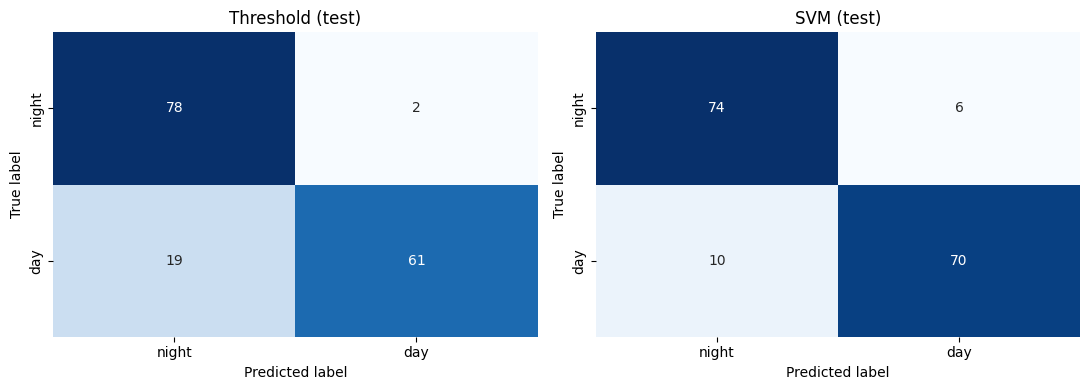

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, pred, title in [
    (axes[0], y_test_threshold, 'Threshold (test)'),
    (axes[1], y_test_pred, 'SVM (test)'),
]:
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt='d', cbar=False, cmap='Blues',
                xticklabels=['night', 'day'],
                yticklabels=['night', 'day'], ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('True label')

plt.tight_layout()
plt.show()

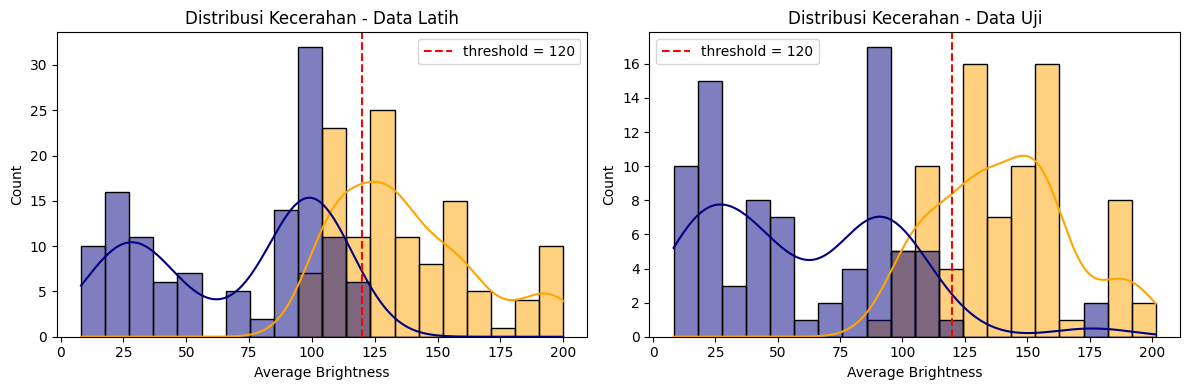

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, df, title in [
    (axes[0], train_avg_img, 'Data Latih'),
    (axes[1], test_avg_img, 'Data Uji'),
]:
    sns.histplot(data=df, x='AVG_BRIGHT', hue='LABELS',
                 bins=20, kde=True, palette={0: 'navy', 1: 'orange'}, ax=ax)
    ax.axvline(120, color='red', linestyle='--', label='threshold = 120')
    ax.set_title(f'Distribusi Kecerahan - {title}')
    ax.set_xlabel('Average Brightness')
    ax.legend()

plt.tight_layout()
plt.show()

In [42]:
from sklearn.metrics import precision_score, recall_score, f1_score


def metrics_row(name, y_true, y_pred):
    return {
        'Metode': name,
        'Akurasi': accuracy_score(y_true, y_pred),
        'Precision (day)': precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        'Recall (day)': recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        'F1 (day)': f1_score(y_true, y_pred, pos_label=1, zero_division=0),
    }


perbandingan = pd.DataFrame([
    metrics_row('Threshold (train)', y_train, y_train_threshold),
    metrics_row('Threshold (test)', y_test, y_test_threshold),
    metrics_row('SVM (train)', y_train, y_train_pred),
    metrics_row('SVM (test)', y_test, y_test_pred),
])

perbandingan.round(4)

,Metode,Akurasi,Precision (day),Recall (day),F1 (day)
0,Threshold (train),0.8417,1.0000,0.6833,0.8119
1,Threshold (test),0.8688,0.9683,0.7625,0.8531
2,SVM (train),0.8583,0.8583,0.8583,0.8583
3,SVM (test),0.9000,0.9211,0.8750,0.8974


# Analisis Hasil

Seluruh angka pada bagian ini diambil dari output aktual notebook.

## Ringkasan Dataset

| Split | Day | Night | Total |
|---|---:|---:|---:|
| Training | 120 | 120 | 240 |
| Test | 80 | 80 | 160 |

Dataset berhasil ditemukan otomatis di `/content/drive/MyDrive/dataset ml /images /images`. Semua gambar berhasil dimuat dan diproses ulang ke ukuran **600 x 1100** piksel.

## Hasil Klasifikasi

| Metode | Akurasi Train | Akurasi Test |
|---|---:|---:|
| Threshold 120 | 0.8417 | 0.8688 |
| SVM (RBF, 1 fitur) | 0.8583 | 0.9000 |

Jumlah kesalahan threshold: **38 dari 240** data latih dan **21 dari 160** data uji.

## Perbandingan Metrik (Data Uji)

| Metode | Akurasi | Precision (day) | Recall (day) | F1 (day) |
|---|---:|---:|---:|---:|
| Threshold | 0.8688 | 0.9683 | 0.7625 | 0.8531 |
| SVM | 0.9000 | 0.9211 | 0.8750 | 0.8974 |

## Pembahasan

1. **SVM lebih baik secara keseluruhan.** Akurasi data uji SVM **0.9000**, lebih tinggi **3.12 poin** daripada threshold **0.8688**. F1-score kelas `day` juga naik dari **0.8531** menjadi **0.8974**.

2. **Threshold condong memprediksi `night`.** Pada data latih, recall `night` mencapai **1.00**, sedangkan recall `day` hanya **0.68**. Artinya semua gambar malam benar, tetapi sekitar 32% gambar siang salah diprediksi sebagai malam. Pola yang sama muncul di data uji: recall `night` **0.97** dan recall `day` **0.76**.

3. **Threshold unggul pada precision `day`.** Nilai **0.9683** berarti hampir semua gambar yang diprediksi siang memang siang. Namun recall rendah menunjukkan banyak gambar siang yang terlewat. Threshold bersifat konservatif karena ambang 120 cukup tinggi.

4. **SVM lebih seimbang.** Pada data uji, SVM memperoleh precision dan recall `night` **0.88/0.93** serta `day` **0.92/0.88**. Selisih antar kelas jauh lebih kecil dibanding threshold, sehingga SVM tidak berat sebelah ke salah satu label.

5. **SVM tidak overfitting.** Akurasi latih **0.8583** dan akurasi uji **0.9000** berbeda sekitar **4.17 poin**, dengan data uji justru lebih tinggi. Model dengan satu fitur memang sangat sederhana, sehingga risiko overfitting kecil.

6. **Penyebab utama kesalahan adalah tumpang tindih kecerahan.** Gambar siang yang mendung atau berada di area gelap memiliki brightness rendah, sedangkan malam dengan lampu kota bisa terang. Karena hanya memakai satu fitur, kedua kondisi ini tidak dapat dipisahkan dengan sempurna. Grafik distribusi kecerahan menunjukkan wilayah nilai yang saling beririsan di sekitar threshold.

7. **Contoh acak pada notebook bersifat ilustratif.** Misalnya gambar ke-194 memiliki brightness **99.0812** dengan label `night`, dan gambar ke-89 berlabel `day` tetapi diprediksi `night` oleh threshold. Nilai ini hanya sampel acak, bukan ukuran performa model.

## Kesimpulan

1. **SVM kernel RBF dengan satu fitur kecerahan mengungguli threshold manual** pada data uji, yaitu **0.9000** berbanding **0.8688**.
2. Threshold 120 masih layak sebagai baseline karena sederhana dan cepat, tetapi bias ke kelas `night` dan sangat bergantung pada pemilihan ambang.
3. Keterbatasan utama kedua metode bukan pada classifier, melainkan pada **fitur**. Satu nilai rata-rata kecerahan tidak cukup membedakan siang gelap dan malam terang.
4. Untuk peningkatan berikutnya, fitur dapat ditambah (histogram warna, rasio area gelap/terang, edge density) atau diganti dengan pendekatan CNN yang mempelajari pola citra secara langsung.